# ARCADE Dataset Exploration

This notebook explores the ARCADE coronary angiography dataset, focusing on the SYNTAX coronary artery segmentation task. The objective is to understand the dataset structure and COCO annotations, visualize coronary artery segmentation masks, and perform basic data integrity checks before developing a deep learning model.

## 1. Dataset Loading

The ARCADE dataset is accessed through KaggleHub. This notebook focuses on the `syntax` subset, which provides coronary angiography images and their corresponding segmentation annotations.

In [ ]:
import os
import json
import kagglehub
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw

In [ ]:
# Access the ARCADE dataset attached to the Kaggle notebook
path = kagglehub.dataset_download("nirmalgaud/arcade-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/nirmalgaud/arcade-dataset


## 2. Dataset Structure

The dataset contains two main tasks: `syntax` and `stenosis`. For coronary artery segmentation, we use the `syntax` subset, which is organized into training, validation, and test splits.

Each split contains an `images/` directory and an `annotations/` directory with a COCO-format JSON file.

In [5]:
dataset_folder = os.path.join(path, "arcade")

print(dataset_folder)

contents = os.listdir(dataset_folder)

print(contents)

/kaggle/input/datasets/nirmalgaud/arcade-dataset/arcade
['stenosis', 'syntax']


In [6]:
train_folder = os.path.join(dataset_folder, "syntax", "train")
print(os.listdir(train_folder))

['annotations', 'images']


In [7]:
annotations_folder = os.path.join(train_folder, "annotations")
print(os.listdir(annotations_folder))

['train.json']


## 3. COCO Annotation Exploration

The dataset uses COCO-format annotations, organized into three main sections: `images`, `annotations`, and `categories`.

Each image is identified by a unique ID, which connects it to its corresponding annotations through the `image_id` field. The segmentation field contains polygon coordinates describing annotated regions.

The `syntax` subset defines 26 categories, including anatomical coronary artery segments and a category named `stenosis`.

In [ ]:
annotation_path = os.path.join(annotations_folder, "train.json")

with open(annotation_path, "r") as file:
    data = json.load(file)

print(data.keys())

dict_keys(['images', 'annotations', 'categories'])


In [10]:
print(len(data["images"]))
print(data["images"][0])

1000
{'id': 922, 'width': 512, 'height': 512, 'file_name': '922.png', 'license': 0, 'flickr_url': '', 'coco_url': '', 'date_captured': 0}


In [11]:
print(data["annotations"][0].keys())

dict_keys(['id', 'image_id', 'category_id', 'segmentation', 'area', 'bbox', 'iscrowd', 'attributes'])


In [ ]:
print("Number of categories:", len(data["categories"]))
print("Categories:", [(c["id"], c["name"]) for c in data["categories"]])

[{'id': 1, 'name': '1', 'supercategory': ''}, {'id': 2, 'name': '2', 'supercategory': ''}, {'id': 3, 'name': '3', 'supercategory': ''}, {'id': 4, 'name': '4', 'supercategory': ''}, {'id': 5, 'name': '5', 'supercategory': ''}, {'id': 6, 'name': '6', 'supercategory': ''}, {'id': 7, 'name': '7', 'supercategory': ''}, {'id': 8, 'name': '8', 'supercategory': ''}, {'id': 9, 'name': '9', 'supercategory': ''}, {'id': 10, 'name': '9a', 'supercategory': ''}, {'id': 11, 'name': '10', 'supercategory': ''}, {'id': 12, 'name': '10a', 'supercategory': ''}, {'id': 13, 'name': '11', 'supercategory': ''}, {'id': 14, 'name': '12', 'supercategory': ''}, {'id': 15, 'name': '12a', 'supercategory': ''}, {'id': 16, 'name': '13', 'supercategory': ''}, {'id': 17, 'name': '14', 'supercategory': ''}, {'id': 18, 'name': '14a', 'supercategory': ''}, {'id': 19, 'name': '15', 'supercategory': ''}, {'id': 20, 'name': '16', 'supercategory': ''}, {'id': 21, 'name': '16a', 'supercategory': ''}, {'id': 22, 'name': '16b', 

In [13]:
print(data["annotations"][0]["image_id"])
print(data["annotations"][0]["category_id"])

922
8


## 4. Image and Annotation Visualization

To understand the relationship between angiography images and their annotations, we examine image `922.png` from the training set.

The image has a resolution of 512 × 512 pixels and contains four associated annotations. Their segmentation polygons are drawn over the original angiography to visualize the annotated coronary artery regions.

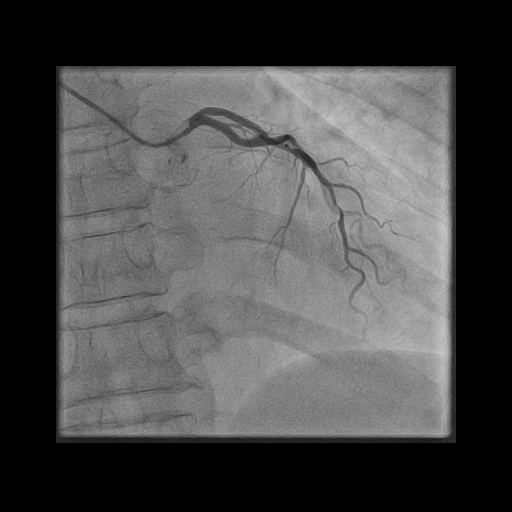

In [ ]:
image_path = os.path.join(train_folder, "images", "922.png")

image = Image.open(image_path)

In [17]:
image_annotations = []

for annotation in data["annotations"]:
    if annotation["image_id"] == 922:
        image_annotations.append(annotation)

print(len(image_annotations))

4


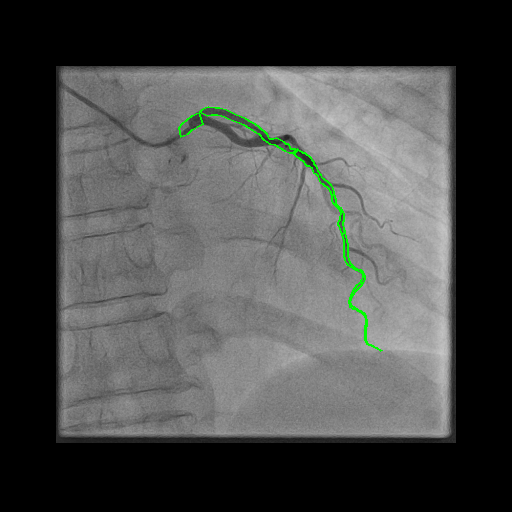

In [ ]:
outlined_image = image.convert("RGB")

draw = ImageDraw.Draw(outlined_image)

for annotation in image_annotations:
    for polygon in annotation["segmentation"]:
        draw.polygon(polygon, outline="lime", width=2)

## 5. Binary Segmentation Mask Generation

The COCO polygon annotations are converted into a binary segmentation mask. Background pixels are assigned a value of 0, while annotated coronary artery regions are assigned 255 for visualization.

The current implementation combines the annotated artery segments into a single foreground class and excludes category 26 (`stenosis`). This category-handling decision will require further validation before model training.

The resulting mask is displayed beside the annotated angiography to visually assess alignment.

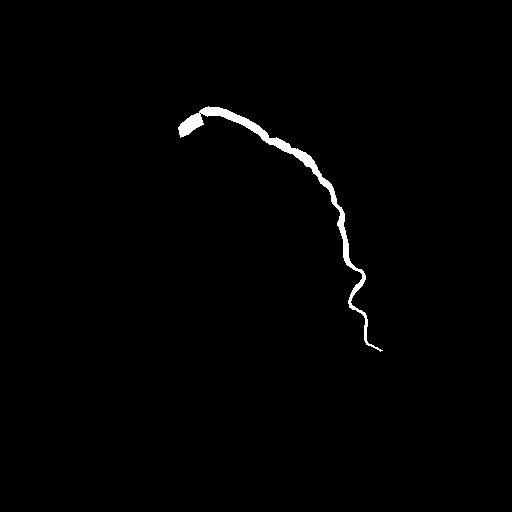

In [ ]:
mask = Image.new("L", image.size, 0)

draw = ImageDraw.Draw(mask)

for annotation in image_annotations:
    if annotation["category_id"] != 26:
        for polygon in annotation["segmentation"]:
            draw.polygon(polygon, fill=255)

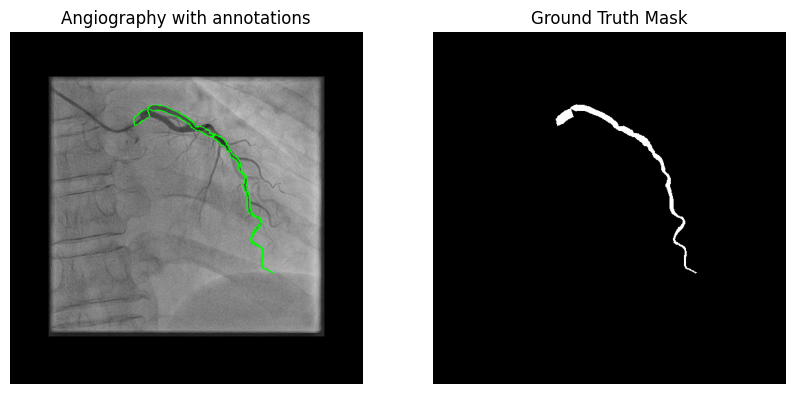

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(outlined_image)
axes[0].set_title("Angiography with annotations")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Ground Truth Mask")

for ax in axes:
    ax.axis("off")

plt.show()

## 6. Dataset Integrity Checks

Basic integrity checks are performed to verify dataset consistency before developing the training pipeline.

The analysis includes counting images and annotations across dataset splits, comparing filenames referenced in the training JSON with actual image files, and verifying that training annotations reference valid image IDs.

These checks help identify missing files and broken annotation references.

In [21]:
for split in ["train", "val", "test"]:
    json_path = os.path.join(dataset_folder, "syntax", split, "annotations", split + ".json")

    with open(json_path, "r") as file:
        split_data = json.load(file)

    print(split, len(split_data["images"]), len(split_data["annotations"]))

train 1000 4976
val 200 1168
test 300 1672


In [22]:
images_folder = os.path.join(train_folder, "images")

image_files = os.listdir(images_folder)

print("Images in JSON:", len(data["images"]))
print("Files in folder:", len(image_files))

Images in JSON: 1000
Files in folder: 1000


In [23]:
json_names = set()

for img in data["images"]:
    json_names.add(img["file_name"])

actual_names = set(image_files)

print("Missing images:", json_names - actual_names)
print("Unexpected images:", actual_names - json_names)

Missing images: set()
Unexpected images: set()


In [24]:
image_ids = set()

for img in data["images"]:
    image_ids.add(img["id"])

invalid_annotations = 0

for annotation in data["annotations"]:
    if annotation["image_id"] not in image_ids:
        invalid_annotations += 1

print("Invalid image references:", invalid_annotations)

Invalid image references: 0


## 7. Findings and Limitations

### Dataset Summary

| Split | Images | Annotations |
|---|---:|---:|
| Train | 1,000 | 4,976 |
| Validation | 200 | 1,168 |
| Test | 300 | 1,672 |
| **Total** | **1,500** | **7,816** |

### Key Findings

- The dataset follows a COCO annotation structure.
- Segmentation annotations are represented using polygons.
- Image `922.png` contains four annotations, successfully visualized and converted into a binary mask.
- The training split contains 1,000 image records and 1,000 corresponding image files.
- No missing or unexpected filenames were identified in the training split.
- All 4,976 training annotations reference valid image IDs.

### Limitations

- Visual inspection was performed on only one image.
- File integrity checks have not yet been extended to validation and test images.
- Patient-level independence between dataset splits has not been verified.
- The appropriate handling of stenosis annotations requires further investigation.
- Additional mask validation is necessary before model training.

### Next Steps

The next stage will focus on implementing a reproducible data-loading and preprocessing pipeline using Python and PyTorch.